# 02 · Cleaning the data (pipeline step 3)

**What this step does**
1. Cut every recording at time jumps larger than `data.max_gap_s`. Nothing is filled in across a jump.
2. Resample every piece to a fixed rate (positions linearly, rotations with SLERP, grip with the nearest value).
3. Convert positions from centimetres to metres.

**Input:** the raw recordings. **Output:** one `.npz` file per segment and `manifest.csv` in `data/interim/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from strikefit_ml.ingestion import ENTITIES, QUAT, list_recordings, load_config, load_recording, recording_stem, resolve
from strikefit_ml.preprocessing import build_interim, load_segments, preprocess_file, split_at_gaps

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures = resolve(cfg, "figures_dir")
figures.mkdir(parents=True, exist_ok=True)
files = list_recordings(resolve(cfg, "raw_dir"))
print(f"rate {cfg['sample_rate_hz']} Hz | longest allowed jump {cfg['data']['max_gap_s']} s | unit scale {cfg['units_scale_to_m']}")

rate 20 Hz | longest allowed jump 0.1 s | unit scale 0.01


## Before and after on one recording
Grey dots are the raw samples (about 90 Hz, converted to metres). Red dots are the resampled frames.

capture_20170811093544021.csv -> 1 segment(s) with [2252] frames


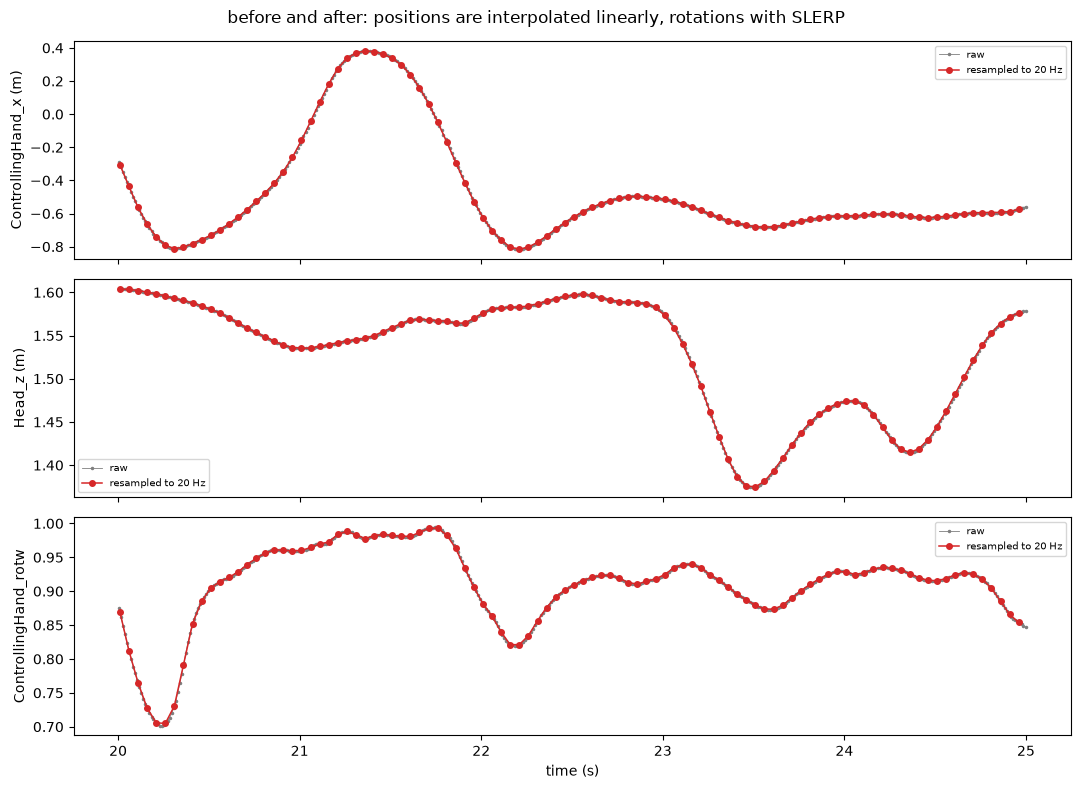

In [2]:
path = files[2]
raw = load_recording(path)
segments = preprocess_file(path, cfg)
print(f"{path.name} -> {len(segments)} segment(s) with {[s.frames for s in segments]} frames")

segment = segments[0].data
# The first segment starts at the raw time of its first row, which is after the jump at the start of the file.
pieces = [(a, b) for a, b in split_at_gaps(raw.Time.to_numpy(), cfg["data"]["max_gap_s"]) if b - a >= cfg["data"]["min_segment_frames"]]
offset = raw.Time.iloc[pieces[0][0]]
start, end = 20.0, 25.0  # five seconds from the middle of the recording

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for axis, column, scale, label in (
    (ax[0], "ControllingHand_x", cfg["units_scale_to_m"], "ControllingHand_x (m)"),
    (ax[1], "Head_z", cfg["units_scale_to_m"], "Head_z (m)"),
    (ax[2], "ControllingHand_rotw", 1, "ControllingHand_rotw"),
):
    shown_raw = raw[(raw.Time > start) & (raw.Time < end)]
    shown = segment[(segment.Time + offset > start) & (segment.Time + offset < end)]
    axis.plot(shown_raw.Time, shown_raw[column] * scale, ".-", ms=3, lw=0.6, color="tab:gray", label="raw")
    axis.plot(shown.Time + offset, shown[column], "o-", ms=4, lw=1.1, color="tab:red", label=f"resampled to {cfg['sample_rate_hz']} Hz")
    axis.set_ylabel(label)
    axis.legend(fontsize=7)
ax[2].set_xlabel("time (s)")
fig.suptitle("before and after: positions are interpolated linearly, rotations with SLERP")
fig.tight_layout()
fig.savefig(figures / "preprocess_before_after.png", dpi=130)
plt.show()

In [3]:
quaternions = segment[[f"{e}_{c}" for e in ENTITIES for c in QUAT]].to_numpy().reshape(len(segment), 3, 4)
print("largest distance of a quaternion's length from 1 after SLERP:", float(np.abs(np.linalg.norm(quaternions, axis=2) - 1).max()))
print("time step is constant:", np.unique(np.round(np.diff(segment.Time), 9)), "| starts at", segment.Time.iloc[0])
print("grip values after resampling:", segment.Grip.unique())

largest distance of a quaternion's length from 1 after SLERP: 2.220446049250313e-16
time step is constant: [0.05] | starts at 0.0
grip values after resampling: [1.]


## The time jump at the start of each recording
Notebook 01 showed that the only jumps larger than 100 ms are between row 0 and row 1, and only some recordings have one.
In those recordings row 0 is alone before the jump and cannot be resampled, so it is dropped and the first segment starts at row 1.
No other data is lost.

In [4]:
rows = []
for path in files:
    recording = load_recording(path)
    pieces = split_at_gaps(recording.Time.to_numpy(), cfg["data"]["max_gap_s"])
    used = [(a, b) for a, b in pieces if b - a >= cfg["data"]["min_segment_frames"]]
    rows.append(
        {
            "recording": recording_stem(path),
            "raw_rows": len(recording),
            "jumps": len(pieces) - 1,
            "jump_after_row": [int(a) - 1 for a, _ in pieces[1:]],
            "segments": len(used),
            "raw_rows_dropped": len(recording) - sum(b - a for a, b in used),
        }
    )
pd.DataFrame(rows)

,recording,raw_rows,jumps,jump_after_row,segments,raw_rows_dropped
0,capture_20170811093232391,7630,0,[],1,0
1,capture_20170811093351273,7054,1,[0],1,1
2,capture_20170811093544021,10082,1,[0],1,1
3,capture_20170811093649846,5882,1,[0],1,1
4,capture_20170811093813954,7524,0,[],1,0
5,capture_20170811093916024,6847,1,[0],1,1
6,capture_20170811094419924,10726,0,[],1,0
7,capture_20170811094603111,9220,1,[0],1,1


## Save the result in `data/interim/`

In [5]:
segments, manifest = build_interim(cfg)
manifest["minutes"] = manifest.duration_s / 60
print(f"{len(segments)} segments | {int(manifest.frames.sum())} frames | {manifest.minutes.sum():.2f} minutes")
manifest

8 segments | 14513 frames | 12.09 minutes


,segment,source_file,segment_index,frames,duration_s,minutes
0,capture_20170811093232391__seg00,capture_20170811093232391,0,1705,85.200,1.420
1,capture_20170811093351273__seg00,capture_20170811093351273,0,1576,78.750,1.312
2,capture_20170811093544021__seg00,capture_20170811093544021,0,2252,112.550,1.876
3,capture_20170811093649846__seg00,capture_20170811093649846,0,1314,65.650,1.094
4,capture_20170811093813954__seg00,capture_20170811093813954,0,1682,84.050,1.401
5,capture_20170811093916024__seg00,capture_20170811093916024,0,1529,76.400,1.273
6,capture_20170811094419924__seg00,capture_20170811094419924,0,2396,119.750,1.996
7,capture_20170811094603111__seg00,capture_20170811094603111,0,2059,102.900,1.715


In [6]:
# Check that reading the saved files gives back the same segments (the files store float32, so allow a tiny difference).
reloaded = load_segments(resolve(cfg, "interim_dir"))
assert [s.name for s in reloaded] == [s.name for s in segments]
assert all(np.allclose(a.data.to_numpy(), b.data.to_numpy(), atol=1e-5) for a, b in zip(reloaded, segments))
print("the saved files give back identical segments")

the saved files give back identical segments
